In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
keras.utils.set_random_seed(42)

In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [4]:
print(x_train.shape, y_train.shape)

(60000, 28, 28) (60000,)


In [5]:
print(x_test.shape, y_test.shape)

(10000, 28, 28) (10000,)


In [6]:
y_train[:10]

array([9, 0, 0, 3, 0, 2, 7, 2, 5, 5], dtype=uint8)

In [7]:
labels = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle Boot"]

In [8]:
labels[y_train[0]]

'Ankle Boot'

In [9]:
print(x_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0
    0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62
   54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134
  144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178
  107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216
  216 163 127 121 122 146 141  88 172  66]
 [  0   0   0   0   0   0   0   0   0   1   1   1   0 200 232 23

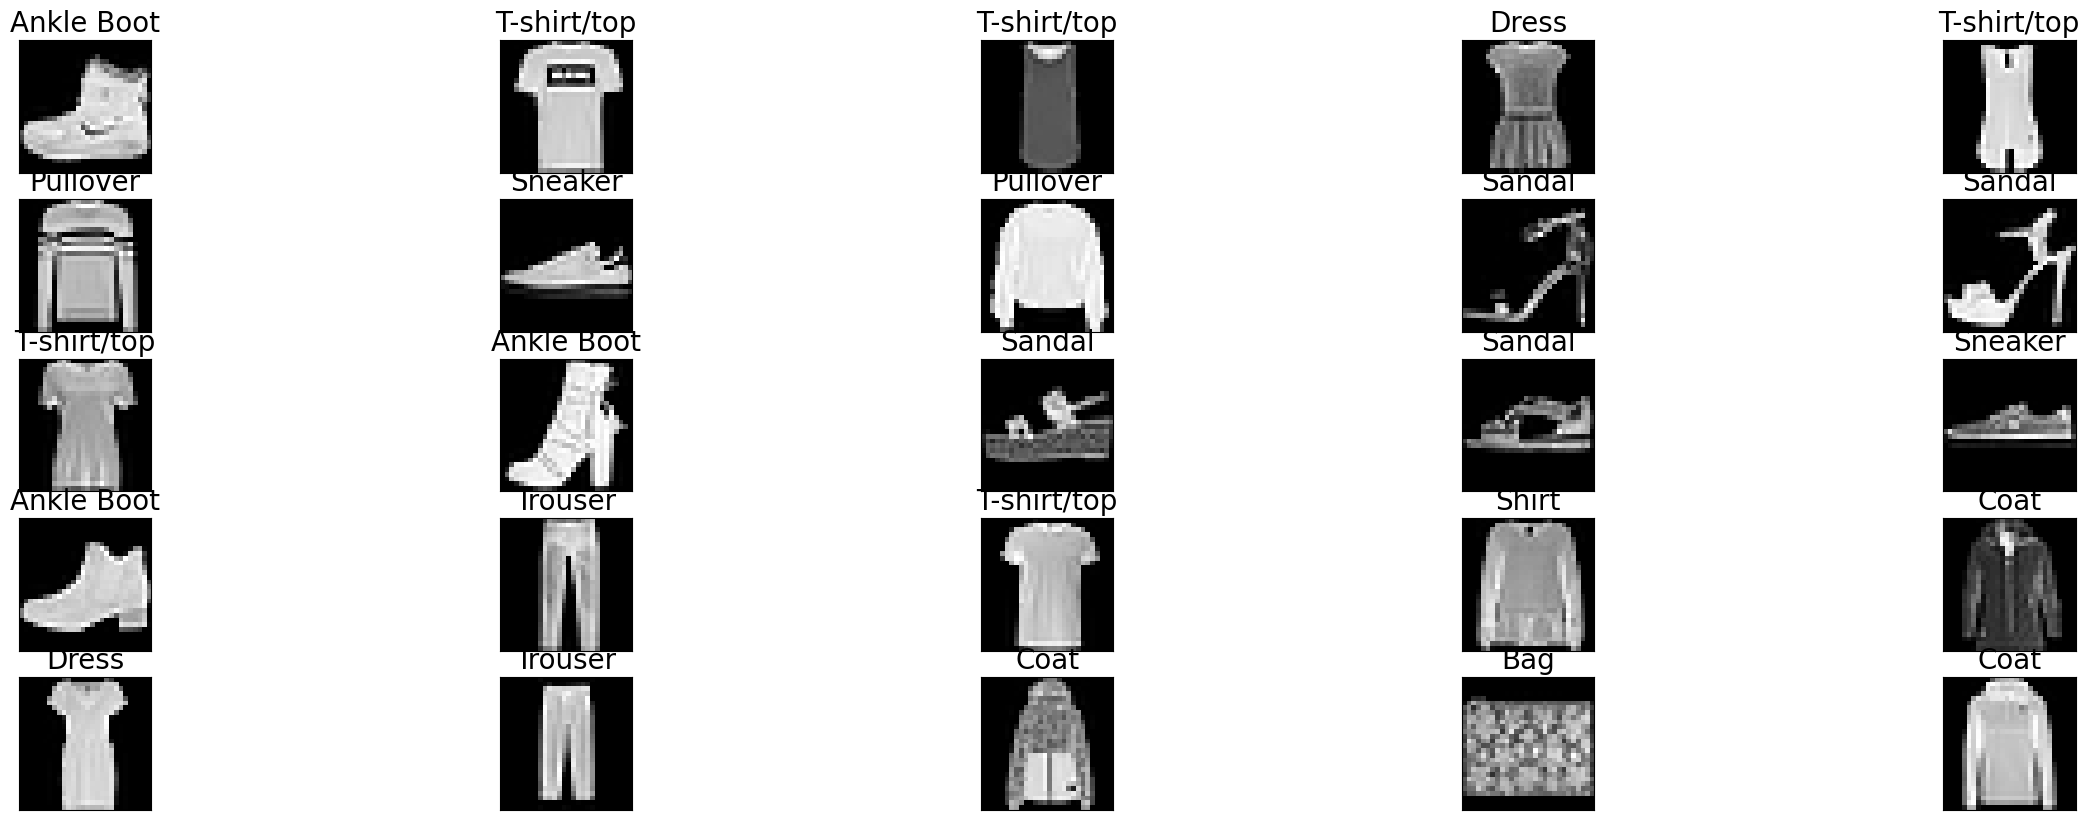

In [10]:
fig, ax = plt.subplots(5,5,figsize=(30,10))
for i in range(25):
  axc = ax[i//5, i%5]
  axc.imshow(x_train[i], cmap='gray')
  axc.set_title(labels[y_train[i]], fontsize=20)
  axc.set_xticks([])
  axc.set_yticks([])

In [11]:
def plot_loss_curves(history):
  plt.clf()
  history.dict = history.history
  loss_values = history.dict['loss']
  val_loss_values = history.dict['val_loss']
  epochs = range(1, len(loss_values)+1)
  plt.plot(epochs, loss_values, "bo", label='Training Loss')
  plt.plot(epochs, val_loss_values, "b", label='Validation Loss')
  plt.title('Training and Validation Loss')
  plt.xlabel('Epochs')
  plt.ylabel('Loss')
  plt.legend()
  plt.show()

In [12]:
def plot_acc_curves(history):
  plt.clf()
  history.dict = history.history
  acc = history.dict['accuracy']
  val_acc = history.dict['val_accuracy']
  epochs = range(1, len(acc)+1)
  plt.plot(epochs, acc, "bo", label='Training Accuracy')
  plt.plot(epochs, val_acc, "b", label='Validation Accuracy')
  plt.title('Training and Validation Accuracy')
  plt.xlabel('Epochs')
  plt.ylabel('Accuracy')
  plt.legend()
  plt.show()

In [13]:
x_train = x_train/ 255.0
x_test = x_test/ 255.0
x_train.shape

(60000, 28, 28)

In [14]:
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)
x_train.shape

(60000, 28, 28, 1)

In [15]:
input = keras.layers.Input(shape=x_train.shape[1:])

In [17]:
x = keras.layers.Conv2D(filters=32, kernel_size=(2,2), activation='relu', name="Conv_1")(input)
x = keras.layers.MaxPool2D()(x)

x = keras.layers.Conv2D(filters=32, kernel_size=(2,2), activation='relu', name="Conv_2")(x)
x = keras.layers.MaxPool2D()(x)

x = keras.layers.Flatten()(x)
x = keras.layers.Dense(256, activation='relu')(x)
output = keras.layers.Dense(10, activation='softmax')(x)

model = keras.Model(inputs=input, outputs=output)

In [18]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_1 (Conv2D)                 │ (None, 27, 27, 32)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_2 (Conv2D)                 │ (None, 12, 12, 32)     │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 302,026 (1.15 MB)

 Trainable params: 302,026 (1.15 MB)

 Non-trainable params: 0 (0.00 B)

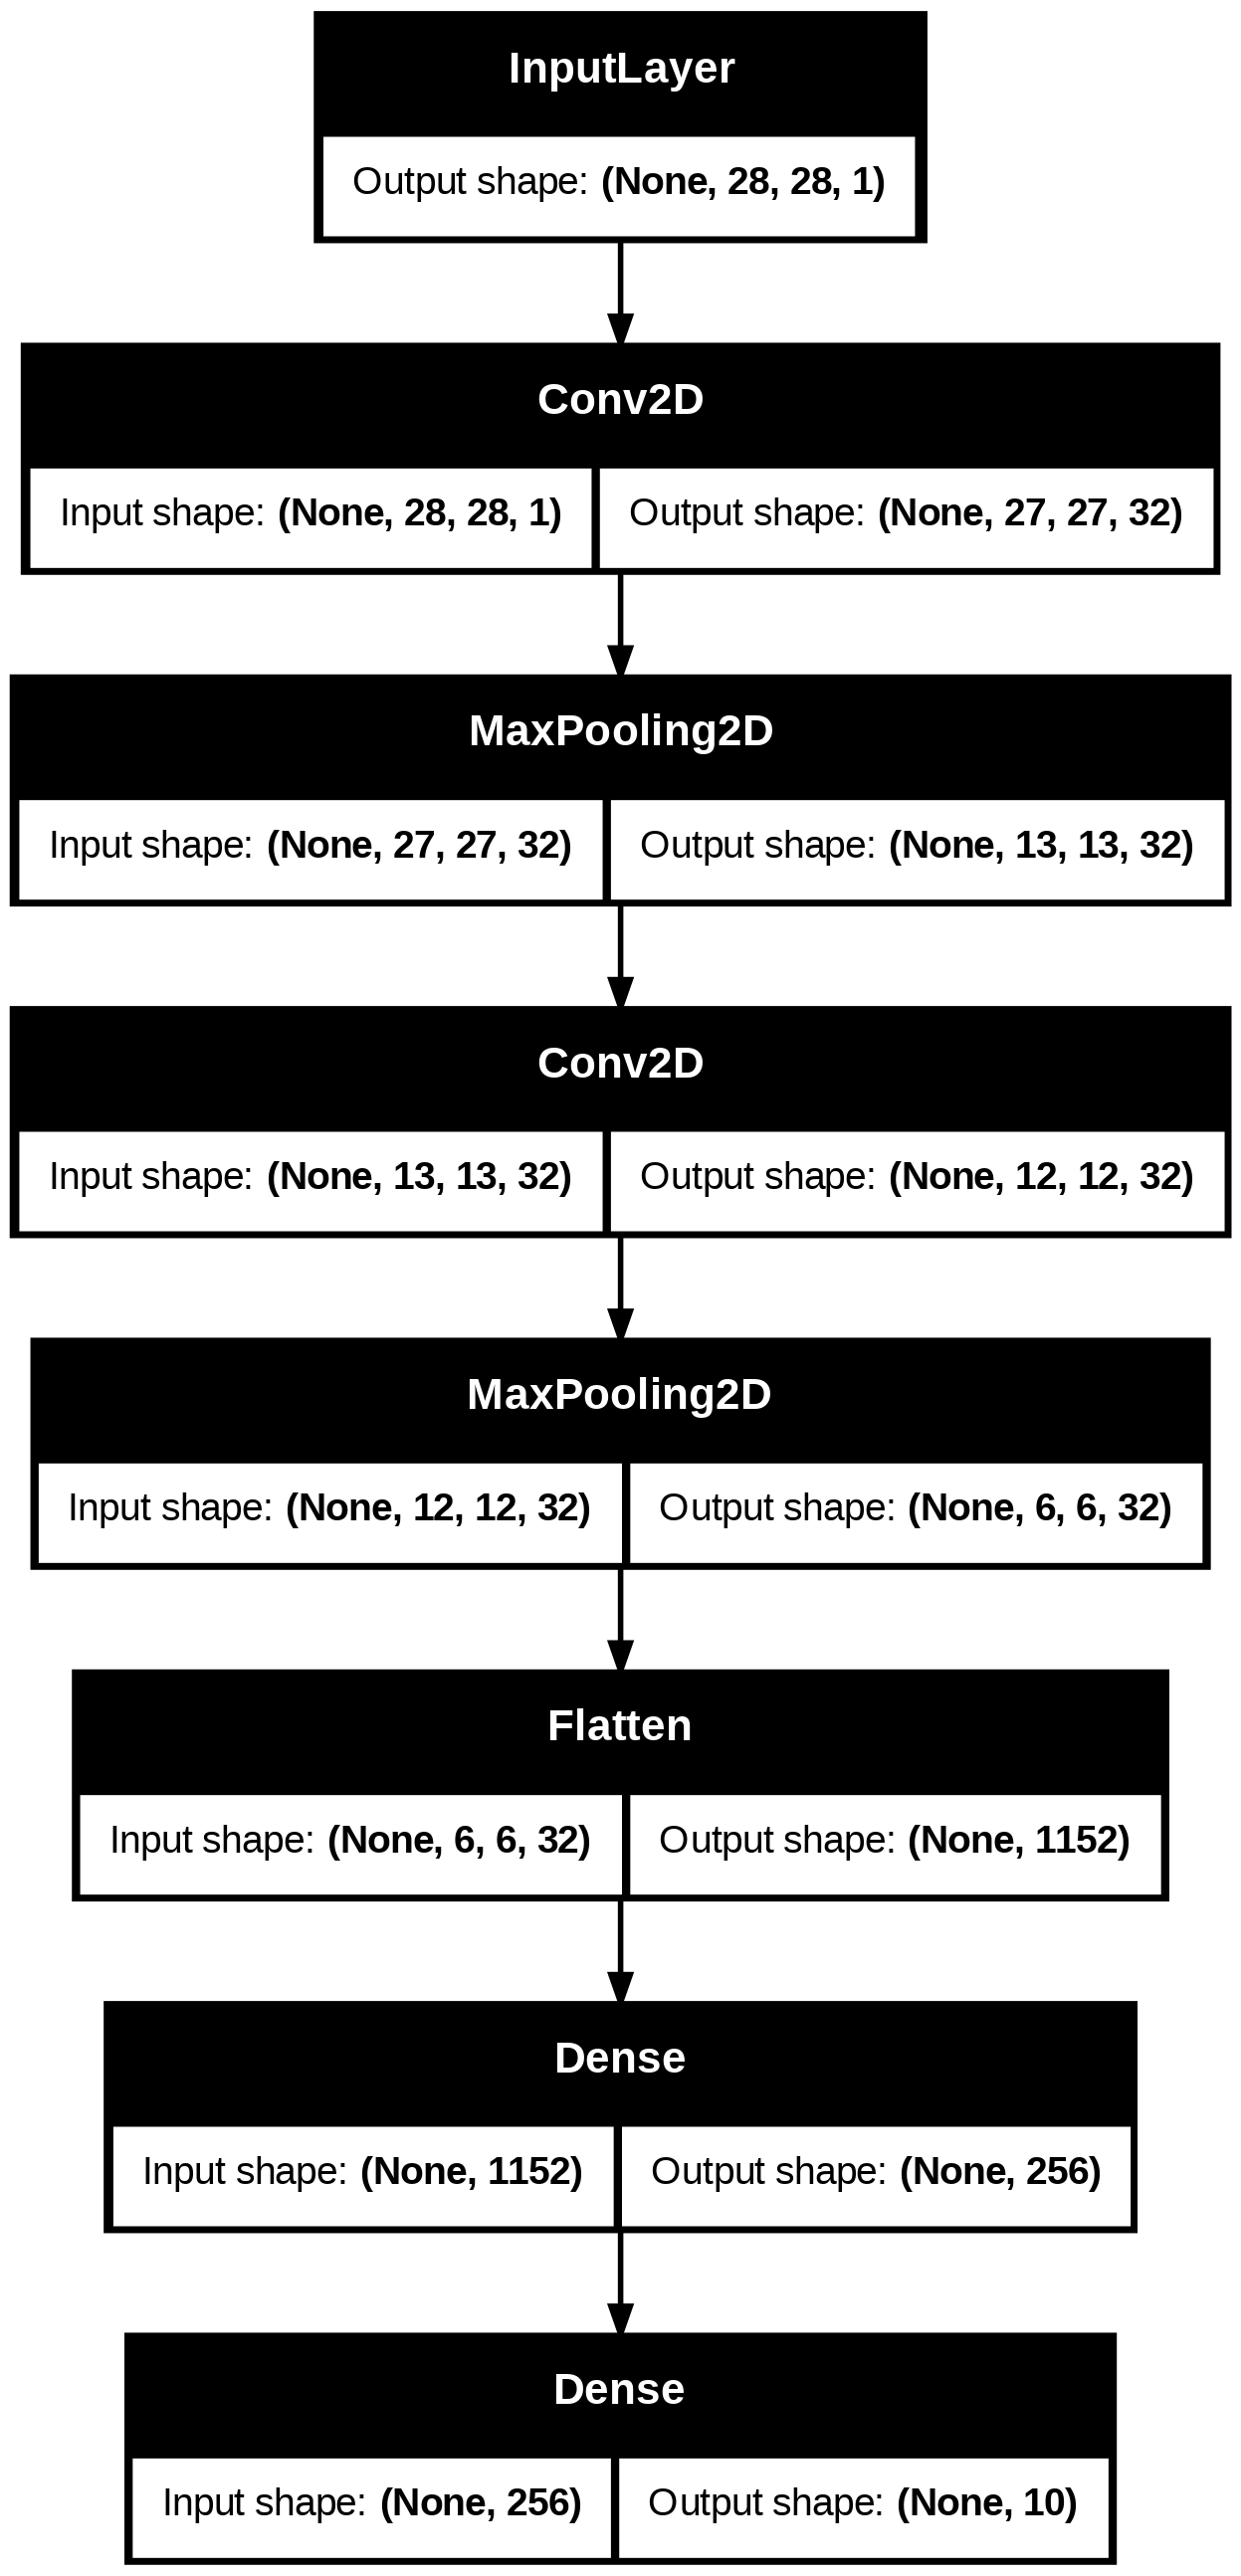

In [19]:
keras.utils.plot_model(model, show_shapes=True)

In [20]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [21]:
history = model.fit(x_train, y_train, batch_size=64, epochs=10, validation_split=0.2)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7474 - loss: 0.7085 - val_accuracy: 0.8701 - val_loss: 0.3705
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8733 - loss: 0.3570 - val_accuracy: 0.8878 - val_loss: 0.3107
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8916 - loss: 0.3008 - val_accuracy: 0.8950 - val_loss: 0.2818
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9039 - loss: 0.2651 - val_accuracy: 0.9003 - val_loss: 0.2656
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9134 - loss: 0.2381 - val_accuracy: 0.9026 - val_loss: 0.2584
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9215 - loss: 0.2162 - val_accuracy: 0.9068 - val_loss: 0.2570
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9285 - loss: 0.1962 - val_accuracy: 0.9059 - val_loss: 0.2594
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9363 - loss: 0.1773 - val_accuracy: 0.

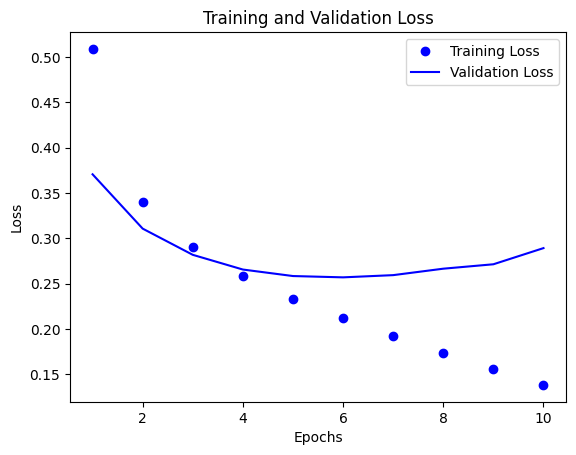

In [22]:
plot_loss_curves(history)

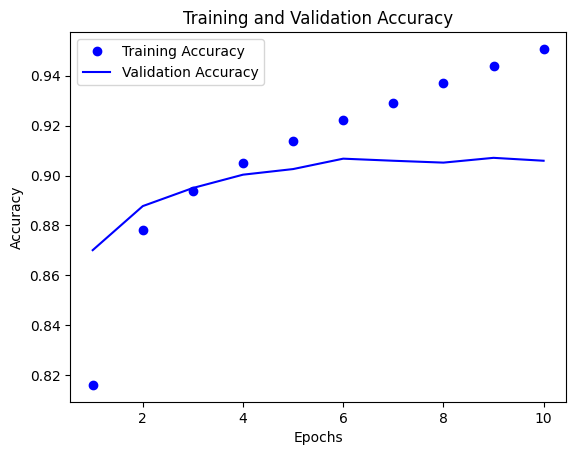

In [23]:
plot_acc_curves(history)

In [24]:
score = model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8942 - loss: 0.3127


In [25]:
print("Test Loss: ", score[0])
print("Test Accuracy: ", score[1])

Test Loss:  0.30386587977409363
Test Accuracy:  0.8985000252723694
